### Notebook for developing Spherical Cauchy distribution

In [1]:
import numpy as np
import spheremix as smix
import matplotlib.pyplot as plt

from loguru import logger

#### Generate samples on the unit sphere

2026-03-29 17:29:16.085 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:151 - Constant:     24593.357804376432
2026-03-29 17:29:16.086 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:152 - Numerator:    -80.3926364921581
2026-03-29 17:29:16.088 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:153 - Denominator:  [-208.96469995 -234.48360279 -238.70514277 -248.62950469 -251.91748751
 -238.60470631 -240.96015196 -260.83066677 -224.50584543 -268.94648871]
2026-03-29 17:29:16.091 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:151 - Constant:     24593.357804376432
2026-03-29 17:29:16.094 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:152 - Numerator:    -80.3926364921581
2026-03-29 17:29:16.095 | INFO     | spheremix.distributions.spherical_cauchy:spherical_cauchy_logpdf:153 - Denominator:  [-208.96469995 -234.48360279 -238.70514277 -248.629

X shape: (10, 8000)
Norms close to 1: True
logpdf range: 24721.92986783836 24781.911656595224
pdf range: inf inf


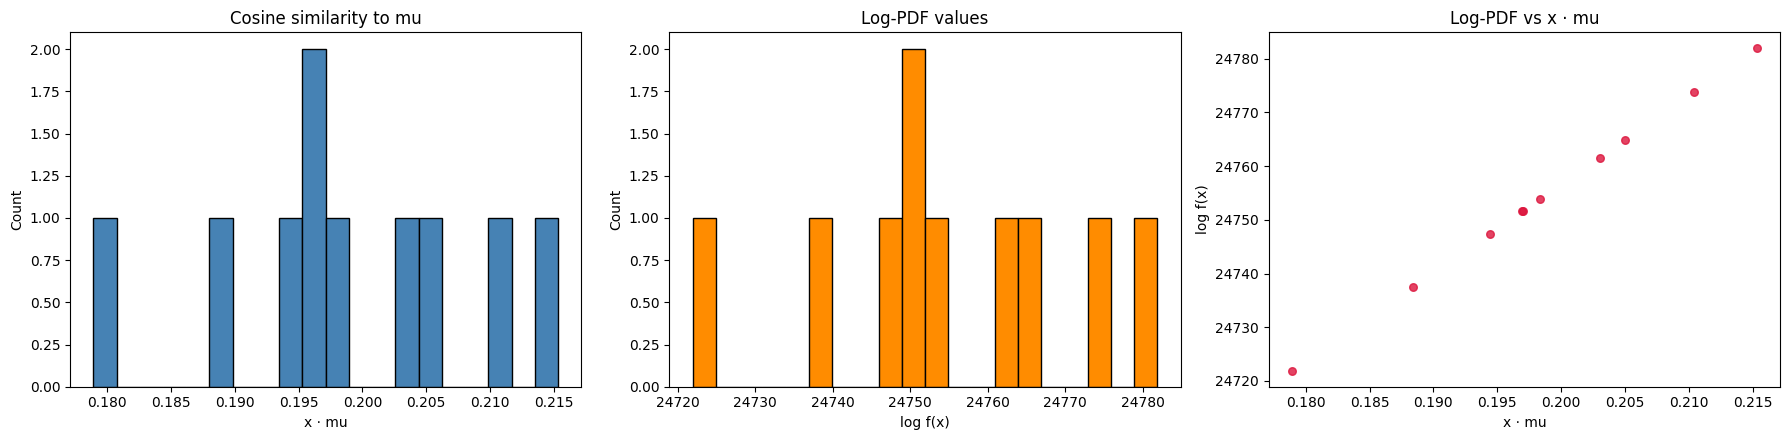

In [3]:
# ---------------------------
# Example: 100 samples in 4000D
# ---------------------------
rng = np.random.default_rng(42)

N = 10
D = 8000
rho = 0.10

# Create a random unit vector mu
mu = rng.normal(size=D)
mu /= np.linalg.norm(mu)

# Sample data
X = smix.distributions.sample_spherical_cauchy(N, mu, rho, rng=rng)

# Evaluate densities
logpdf_vals = smix.distributions.spherical_cauchy_logpdf(X, mu, rho)
pdf_vals = smix.distributions.spherical_cauchy_pdf(X, mu, rho)


logger.info(X)

print("X shape:", X.shape)
print("Norms close to 1:", np.allclose(np.linalg.norm(X, axis=1), 1.0, atol=1e-8))
print("logpdf range:", logpdf_vals.min(), logpdf_vals.max())
print("pdf range:", pdf_vals.min(), pdf_vals.max())

# Useful diagnostic: alignment with mu
cos_vals = X @ mu

# ---------------------------
# Visualization
# ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].hist(cos_vals, bins=20, color="steelblue", edgecolor="black")
axes[0].set_title("Cosine similarity to mu")
axes[0].set_xlabel("x · mu")
axes[0].set_ylabel("Count")

axes[1].hist(logpdf_vals, bins=20, color="darkorange", edgecolor="black")
axes[1].set_title("Log-PDF values")
axes[1].set_xlabel("log f(x)")
axes[1].set_ylabel("Count")

axes[2].scatter(cos_vals, logpdf_vals, s=30, alpha=0.8, color="crimson")
axes[2].set_title("Log-PDF vs x · mu")
axes[2].set_xlabel("x · mu")
axes[2].set_ylabel("log f(x)")

plt.tight_layout()
plt.show()